# Titanic Dataset: Data Cleaning Walkthrough

**Author:** Faith Njah

This notebook cleans the Titanic passenger dataset and prepares it for analysis. Each step shows what was found in the data, the decision taken and the reason for it.

**Dataset:** [Titanic: Machine Learning from Disaster (Kaggle)](https://www.kaggle.com/c/titanic/data): 891 passengers with their ticket class, name, sex, age, family aboard, fare, cabin, port of embarkation and whether they survived.

**Steps**
1. Load and explore the data
2. Classify the features
3. Handle missing values
4. Handle outliers
5. Handle duplicates
6. Fix inconsistent data types
7. Feature engineering
8. Quick look at survival patterns
9. Save and summarise

## 1. Setup and load the data

In [1]:
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style="whitegrid")
FIG_DIR = Path("../figures")
FIG_DIR.mkdir(exist_ok=True)

DATA_PATH = Path("../data/titanic.csv")
DATA_URL = "https://raw.githubusercontent.com/datasciencedojo/datasets/master/titanic.csv"

if not DATA_PATH.exists():  # download a public copy on first run
    pd.read_csv(DATA_URL).to_csv(DATA_PATH, index=False)

df = pd.read_csv(DATA_PATH)
print(f"{df.shape[0]} rows x {df.shape[1]} columns")
df.head()

891 rows x 12 columns


,PassengerId,Survived,Pclass,Name,Sex,Age,SibSp,Parch,Ticket,Fare,Cabin,Embarked
0,1,0,3,"Braund, Mr. Owen Harris",male,22.0,1,0,A/5 21171,7.2500,NaN,S
1,2,1,1,"Cumings, Mrs. John Bradley (Florence Briggs Th...",female,38.0,1,0,PC 17599,71.2833,C85,C
2,3,1,3,"Heikkinen, Miss. Laina",female,26.0,0,0,STON/O2. 3101282,7.9250,NaN,S
3,4,1,1,"Futrelle, Mrs. Jacques Heath (Lily May Peel)",female,35.0,1,0,113803,53.1000,C123,S
4,5,0,3,"Allen, Mr. William Henry",male,35.0,0,0,373450,8.0500,NaN,S


In [2]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 891 entries, 0 to 890
Data columns (total 12 columns):
 #   Column       Non-Null Count  Dtype  
---  ------       --------------  -----  
 0   PassengerId  891 non-null    int64  
 1   Survived     891 non-null    int64  
 2   Pclass       891 non-null    int64  
 3   Name         891 non-null    str    
 4   Sex          891 non-null    str    
 5   Age          714 non-null    float64
 6   SibSp        891 non-null    int64  
 7   Parch        891 non-null    int64  
 8   Ticket       891 non-null    str    
 9   Fare         891 non-null    float64
 10  Cabin        204 non-null    str    
 11  Embarked     889 non-null    str    
dtypes: float64(2), int64(5), str(5)
memory usage: 83.7 KB


### Data dictionary

| Column | Meaning |
|---|---|
| PassengerId | Unique passenger ID |
| Survived | 0 = No, 1 = Yes |
| Pclass | Ticket class: 1 = Upper, 2 = Middle, 3 = Lower |
| Name | Passenger name, including title (Mr, Mrs, ...) |
| Sex | male / female |
| Age | Age in years |
| SibSp | Number of siblings or spouses aboard |
| Parch | Number of parents or children aboard |
| Ticket | Ticket number |
| Fare | Ticket price |
| Cabin | Cabin number |
| Embarked | Port: C = Cherbourg, Q = Queenstown, S = Southampton |

## 2. Classify the features

| Column | Stored as | Should be | Classification |
|---|---|---|---|
| Survived | int | category | Categorical, nominal (binary) |
| Pclass | int | category | Categorical, **ordinal** (1st > 2nd > 3rd) |
| Name | string | string | Text identifier |
| Sex | string | category | Categorical, nominal |
| Age | float | float | Numerical, continuous |
| SibSp | int | int | Numerical, discrete |
| Parch | int | int | Numerical, discrete |
| Ticket | string | string | Text identifier |
| Fare | float | float | Numerical, continuous |
| Cabin | string | string | Categorical, nominal (mostly missing) |
| Embarked | string | category | Categorical, nominal |

**Mismatched types:** `Survived` and `Pclass` are stored as integers, so `describe()` treats them as quantities and reports a mean and standard deviation that don't mean anything. They are categories and are converted in step 6.

In [3]:
df.describe().round(2)

,PassengerId,Survived,Pclass,Age,SibSp,Parch,Fare
count,891.00,891.00,891.00,714.00,891.00,891.00,891.00
mean,446.00,0.38,2.31,29.70,0.52,0.38,32.20
std,257.35,0.49,0.84,14.53,1.10,0.81,49.69
min,1.00,0.00,1.00,0.42,0.00,0.00,0.00
25%,223.50,0.00,2.00,20.12,0.00,0.00,7.91
50%,446.00,0.00,3.00,28.00,0.00,0.00,14.45
75%,668.50,1.00,3.00,38.00,1.00,0.00,31.00
max,891.00,1.00,3.00,80.00,8.00,6.00,512.33


## 3. Handle missing values
All cleaning is done on a copy so the raw data stays untouched.

In [4]:
data = df.copy()

missing = data.isnull().sum().to_frame("missing")
missing["percent"] = (missing["missing"] / len(data) * 100).round(1)
missing[missing["missing"] > 0]

,missing,percent
Age,177,19.9
Cabin,687,77.1
Embarked,2,0.2


Three columns have gaps, and each needs a different strategy:

| Column | Missing | Strategy |
|---|---|---|
| Age | ~20% | Too many rows to drop → **impute** |
| Cabin | ~77% | Too sparse to impute without inventing data → **drop**, but keep a "had a cabin" flag |
| Embarked | 2 rows | Tiny gap → **fill with the most common port** |

Dropping every incomplete row (`dropna()`) would leave only 183 of 891 passengers, so it isn't an option.

### 3a. Age
Age is right-skewed, so the median is safer than the mean. Even better, the passenger's **title** (Mr, Mrs, Miss, Master) is a strong clue to age: "Master" was used for young boys. Each missing age is filled with the median age of passengers who share that title.

In [5]:
data["Title"] = data["Name"].str.extract(r",\s*([^.]+)\.", expand=False).str.strip()
data["Title"] = data["Title"].replace({
    "Mlle": "Miss", "Ms": "Miss", "Mme": "Mrs",
    "Lady": "Rare", "the Countess": "Rare", "Capt": "Rare", "Col": "Rare",
    "Don": "Rare", "Dr": "Rare", "Major": "Rare", "Rev": "Rare",
    "Sir": "Rare", "Jonkheer": "Rare", "Dona": "Rare",
})
data.groupby("Title")["Age"].agg(["count", "median"]).round(1)

,count,median
Title,,
Master,36,3.5
Miss,149,21.0
Mr,398,30.0
Mrs,109,35.0
Rare,22,48.5


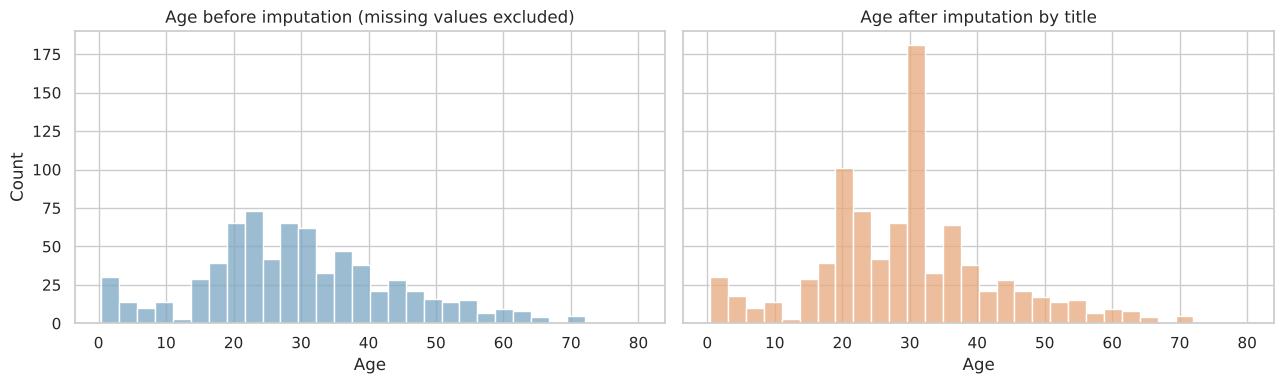

Missing ages left: 0


In [6]:
age_before = data["Age"].copy()
data["Age"] = data["Age"].fillna(data.groupby("Title")["Age"].transform("median"))

fig, axes = plt.subplots(1, 2, figsize=(13, 4), sharey=True)
sns.histplot(age_before.dropna(), bins=30, ax=axes[0], color="#7aa6c2")
axes[0].set_title("Age before imputation (missing values excluded)")
sns.histplot(data["Age"], bins=30, ax=axes[1], color="#e8a87c")
axes[1].set_title("Age after imputation by title")
fig.tight_layout()
fig.savefig(FIG_DIR / "age_imputation.png", dpi=120)
plt.show()

print("Missing ages left:", data["Age"].isnull().sum())

**Observation:** filling every gap with one overall median would give all 177 passengers the same age. Filling by title spreads them across several ages instead: boys labelled "Master" get about 3.5 years, "Miss" 21, "Mr" 30 and "Mrs" 35. The remaining spike at 30 comes from the large number of adult men whose age was missing. That limitation is worth knowing about; a model-based imputation could reduce it.

### 3b. Cabin

In [7]:
data["HasCabin"] = data["Cabin"].notna().astype(int)
data = data.drop(columns=["Cabin"])
data.groupby("HasCabin")["Survived"].mean().round(2).rename("survival rate")

HasCabin
0    0.30
1    0.67
Name: survival rate, dtype: float64

**Observation:** the cabin number itself is too sparse to use, but *whether* a cabin was recorded matters: those passengers (mostly first class) survived far more often. The flag keeps that signal without inventing cabin numbers.

### 3c. Embarked

In [8]:
print(data.loc[data["Embarked"].isnull(), ["Name", "Pclass", "Fare"]])
data["Embarked"] = data["Embarked"].fillna(data["Embarked"].mode().iloc[0])
print("\nRemaining missing values in the whole dataset:", int(data.isnull().sum().sum()))

                                          Name  Pclass  Fare
61                         Icard, Miss. Amelie       1  80.0
829  Stone, Mrs. George Nelson (Martha Evelyn)       1  80.0

Remaining missing values in the whole dataset: 0


## 4. Handle outliers

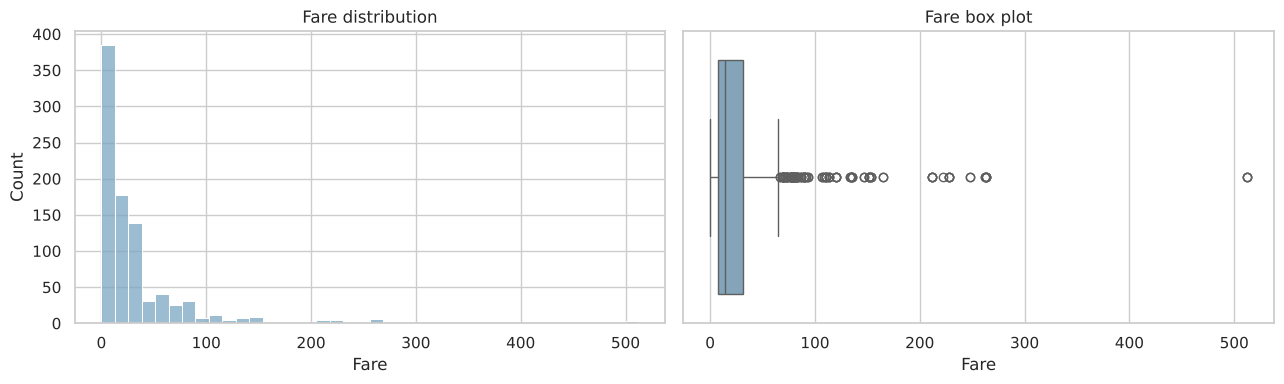

In [9]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4))
sns.histplot(data["Fare"], bins=40, ax=axes[0], color="#7aa6c2")
axes[0].set_title("Fare distribution")
sns.boxplot(x=data["Fare"], ax=axes[1], color="#7aa6c2")
axes[1].set_title("Fare box plot")
fig.tight_layout()
fig.savefig(FIG_DIR / "fare_outliers.png", dpi=120)
plt.show()

In [10]:
q1, q3 = data["Fare"].quantile([0.25, 0.75])
upper = q3 + 1.5 * (q3 - q1)
print(f"IQR upper fence: {upper:.2f}")
print(f"Fares above the fence: {(data['Fare'] > upper).sum()}")
data.loc[data["Fare"] > 500, ["Name", "Pclass", "Ticket", "Fare", "Survived"]]

IQR upper fence: 65.63
Fares above the fence: 116


,Name,Pclass,Ticket,Fare,Survived
258,"Ward, Miss. Anna",1,PC 17755,512.3292,1
679,"Cardeza, Mr. Thomas Drake Martinez",1,PC 17755,512.3292,1
737,"Lesurer, Mr. Gustave J",1,PC 17755,512.3292,1


**Observation:** the IQR rule flags 116 fares as outliers, but these are **genuine values, not errors**. They are first-class tickets, and the three £512 fares all belong to one ticket (PC 17755) shared by a single travelling party. Deleting them would remove real, high-value first-class passengers and bias the data.

**Decision:** keep every row and add a **log-transformed fare** (`FareLog`). This pulls in the long tail so extreme fares don't dominate a model, without throwing away data.

Skewness of Fare:    4.79
Skewness of FareLog: 0.39


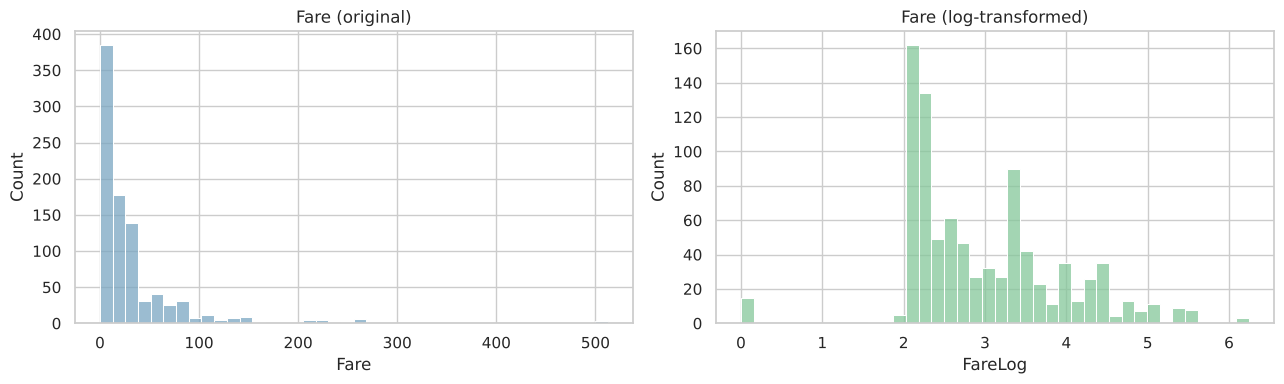

In [11]:
data["FareLog"] = np.log1p(data["Fare"])
print(f"Skewness of Fare:    {data['Fare'].skew():.2f}")
print(f"Skewness of FareLog: {data['FareLog'].skew():.2f}")

fig, axes = plt.subplots(1, 2, figsize=(13, 4))
sns.histplot(data["Fare"], bins=40, ax=axes[0], color="#7aa6c2")
axes[0].set_title("Fare (original)")
sns.histplot(data["FareLog"], bins=40, ax=axes[1], color="#85c79a")
axes[1].set_title("Fare (log-transformed)")
fig.tight_layout()
fig.savefig(FIG_DIR / "fare_log_transform.png", dpi=120)
plt.show()

Skewness drops from about 4.8 to about 0.4, so the distribution becomes close to symmetric.

## 5. Handle duplicates

In [12]:
print("Exact duplicate rows:  ", data.duplicated().sum())
print("Repeated PassengerIds: ", data["PassengerId"].duplicated().sum())
data = data.drop_duplicates().reset_index(drop=True)

Exact duplicate rows:   0
Repeated PassengerIds:  0


**Observation:** there are no duplicates. The check is kept in the pipeline so that it still protects against duplicates if new data is added.

## 6. Fix inconsistent data types

In [13]:
for col in ["Survived", "Pclass", "Sex", "Embarked"]:
    print(f"{col:9s} {str(data[col].dtype):8s} {sorted(data[col].unique())}")

Survived  int64    [np.int64(0), np.int64(1)]
Pclass    int64    [np.int64(1), np.int64(2), np.int64(3)]
Sex       str      ['female', 'male']
Embarked  str      ['C', 'Q', 'S']


In [14]:
data["Survived"] = data["Survived"].astype("category")
data["Pclass"] = pd.Categorical(data["Pclass"], categories=[1, 2, 3], ordered=True)
for col in ["Sex", "Embarked", "Title"]:
    data[col] = data[col].astype("category")
data.dtypes

PassengerId       int64
Survived       category
Pclass         category
Name                str
Sex            category
Age             float64
SibSp             int64
Parch             int64
Ticket              str
Fare            float64
Embarked       category
Title          category
HasCabin          int64
FareLog         float64
dtype: object

**Observation:** the values are already consistent (no typos or mixed spellings), but the types were wrong. `Pclass` is stored as an *ordered* category because 1st > 2nd > 3rd.

## 7. Feature engineering

In [15]:
data["FamilySize"] = data["SibSp"] + data["Parch"] + 1
data["IsAlone"] = (data["FamilySize"] == 1).astype(int)
data[["Name", "SibSp", "Parch", "FamilySize", "IsAlone"]].head()

,Name,SibSp,Parch,FamilySize,IsAlone
0,"Braund, Mr. Owen Harris",1,0,2,0
1,"Cumings, Mrs. John Bradley (Florence Briggs Th...",1,0,2,0
2,"Heikkinen, Miss. Laina",0,0,1,1
3,"Futrelle, Mrs. Jacques Heath (Lily May Peel)",1,0,2,0
4,"Allen, Mr. William Henry",0,0,1,1


## 8. Quick look at survival patterns

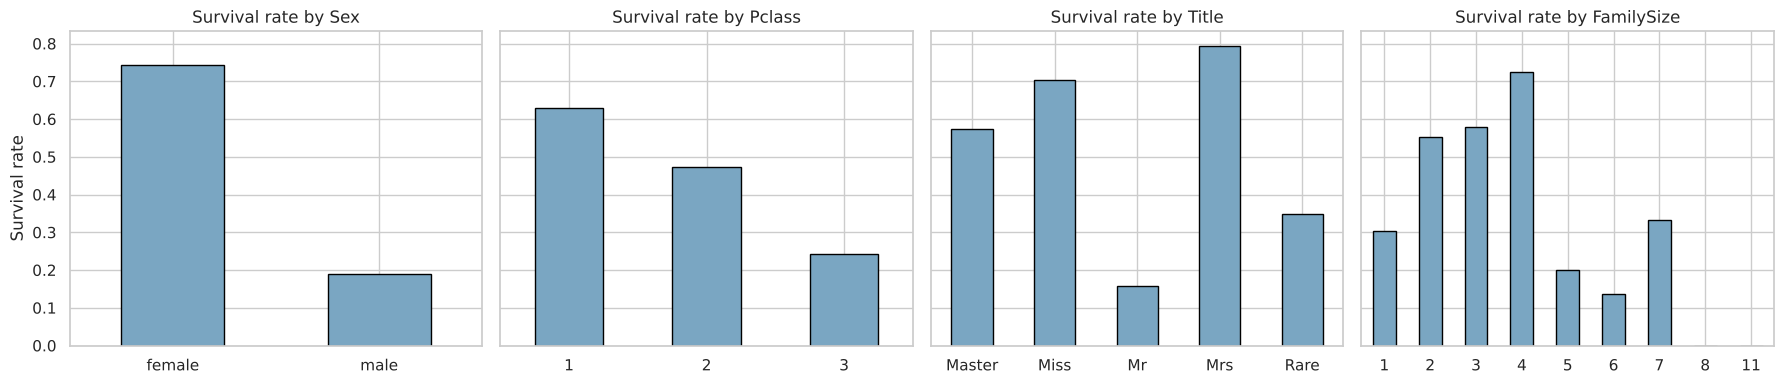

In [16]:
survived = data["Survived"].astype(int)
fig, axes = plt.subplots(1, 4, figsize=(18, 4), sharey=True)
for ax, col in zip(axes, ["Sex", "Pclass", "Title", "FamilySize"]):
    rate = survived.groupby(data[col], observed=True).mean()
    rate.plot.bar(ax=ax, color="#7aa6c2", edgecolor="black")
    ax.set_title(f"Survival rate by {col}")
    ax.set_xlabel("")
    ax.tick_params(axis="x", rotation=0)
axes[0].set_ylabel("Survival rate")
fig.tight_layout()
fig.savefig(FIG_DIR / "survival_patterns.png", dpi=120)
plt.show()

**Observations**
- **Sex:** about 74% of women survived compared with 19% of men ("women and children first").
- **Class:** survival falls from 63% in first class to 24% in third.
- **Title:** "Master" (boys) survived far more often than "Mr", which supports the title-based age imputation.
- **Family size:** small families (2–4 people) did best; people travelling alone and large families did worse.

## 9. Save and summarise

In [17]:
data.to_csv("../data/titanic_clean.csv", index=False)
print(f"Clean dataset: {data.shape[0]} rows x {data.shape[1]} columns, "
      f"{int(data.isnull().sum().sum())} missing values")

Clean dataset: 891 rows x 16 columns, 0 missing values


| Issue | Finding | Action |
|---|---|---|
| Missing Age | 177 rows (20%) | Imputed with the median age for each title |
| Missing Cabin | 687 rows (77%) | Dropped the column; kept a `HasCabin` flag |
| Missing Embarked | 2 rows | Filled with the most common port (S) |
| Fare outliers | 116 above the IQR fence, all genuine | Kept; added `FareLog` (skew 4.8 → 0.4) |
| Duplicates | None | Check kept in the pipeline |
| Wrong types | Survived and Pclass stored as numbers | Converted to categories (Pclass ordered) |
| New features | n/a | `Title`, `FamilySize`, `IsAlone`, `HasCabin`, `FareLog` |

The output, `data/titanic_clean.csv`, has no missing values and is ready for analysis or a survival-prediction model.